# Machine Learning with scikit-learn: A Guided Practical Tutorial

**Course notebook | Supervised classification, evaluation, preprocessing, and model selection**

In this notebook we build a complete machine-learning workflow, starting from a real dataset and ending with an evaluated and reusable classifier. We use the same dataset throughout so that the **API**, rather than the dataset, is the focus.

**Prerequisites:** Python functions, NumPy arrays, pandas DataFrames, and basic classification concepts.

### Learning objectives
By the end, you should be able to:
1. distinguish *features*, *labels*, *estimators*, and *transformers*;
2. inspect a dataset and create a reproducible, stratified train/test split;
3. train and compare several scikit-learn classifiers;
4. interpret accuracy, precision, recall, F1, and confusion matrices;
5. scale features without introducing data leakage;
6. build and inspect pipelines, probabilities, and learned attributes;
7. use cross-validation and tune a hyperparameter **without using the test set**;
8. fit and inspect a simple neural network with `MLPClassifier`, and tune it with `GridSearchCV`.

> **Clinical context:** This is an educational example, **not** a clinically validated diagnostic system. Predictions must not be interpreted as medical advice.

## 0. Setup and roadmap

The workflow we will follow is:

**Inspect data → Split → Fit preprocessing and model on training data → Predict on test data → Evaluate.**

Later we add **cross-validation** and **hyperparameter selection**, always on the training set.

Run the cells from top to bottom. If a package is missing, install it in your environment (e.g. `python -m pip install scikit-learn pandas numpy matplotlib`).

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 12)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

NumPy: 2.5.2
pandas: 3.0.6


## 1. The scikit-learn API: one interface, many algorithms

scikit-learn makes different machine-learning algorithms look similar:

| Object | Main methods | Meaning |
|---|---|---|
| **Estimator** | `fit(X, y)` | Learns from the supplied training examples |
| **Predictor** | `predict(X)`; sometimes `predict_proba(X)` | Predicts labels or estimated class probabilities |
| **Transformer** | `fit(X)`, `transform(X)`, `fit_transform(X)` | Learns a transformation and applies it |
| **Pipeline** | `fit(X, y)`, `predict(X)` | Chains transformers and an estimator |

Here, `X` contains one row per sample and one column per feature. `y` contains the target label for each sample.

**Important distinction:** `fit` does not mean *the same computation* for every object: a scaler learns means and standard deviations; a classifier learns a decision rule.

## 2. Load and understand the dataset

We use scikit-learn’s **Breast Cancer Wisconsin (Diagnostic)** dataset. Features summarize measurements derived from digitized images of cell nuclei. The target is **0 = malignant, 1 = benign**. These labels matter when interpreting precision, recall, and probability columns.

The dataset is supplied with scikit-learn, so no network access is needed.

In [54]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()          # Features (DataFrame)
y = dataset.target.copy()        # Target (Series)

print("Features shape:", X.shape)
print("Targets shape:", y.shape)
print("Class names:", dict(enumerate(dataset.target_names)))
display(X.head())

Features shape: (569, 30)
Targets shape: (569,)
Class names: {0: np.str_('malignant'), 1: np.str_('benign')}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [55]:
print("Number of features:", X.shape[1])
print("Feature types: \n", X.dtypes.value_counts())
print("Missing feature values:", X.isna().sum().sum())
print("\nTarget counts:")
display(y.map({0: "malignant", 1: "benign"}).value_counts().to_frame("count"))
display(X.describe().loc[["mean", "std", "min", "max"], X.columns[:6]])

Number of features: 30
Feature types: 
 float64    30
Name: count, dtype: int64
Missing feature values: 0

Target counts:


,count
target,
benign,357
malignant,212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400


### Quick exploratory visualization

Features are measured in different units and may have very different numerical ranges. The following histogram is for **understanding the data only**; it does not train a model.

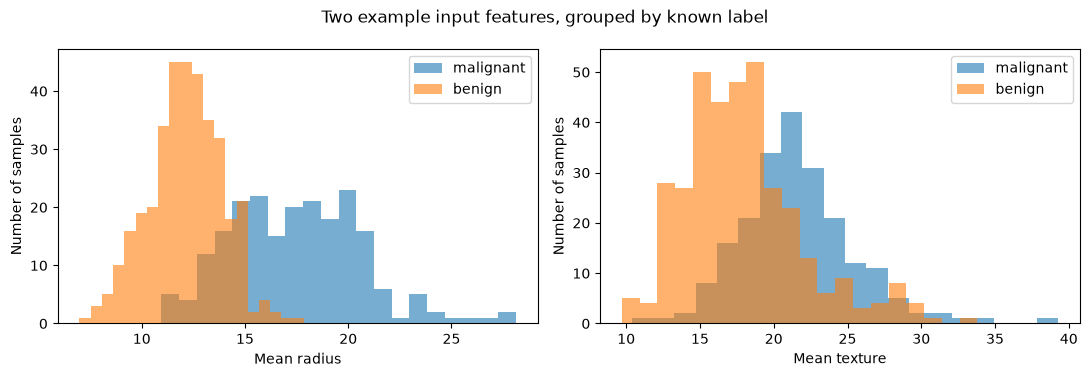

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, name in [(0, "malignant"), (1, "benign")]:
    subset = X.loc[y == label]
    axes[0].hist(subset["mean radius"], bins=20, alpha=0.6, label=name)
    axes[1].hist(subset["mean texture"], bins=20, alpha=0.6, label=name)
for ax in axes:
    ax.set_ylabel("Number of samples")
    ax.legend()
axes[0].set_xlabel("Mean radius")
axes[1].set_xlabel("Mean texture")
fig.suptitle("Two example input features, grouped by known label")
plt.tight_layout()
plt.show()

**Check your understanding:** How many samples are there? Are the two classes equally frequent? Why would a classifier that always predicts the majority class obtain nonzero accuracy?

## 3. Separate training and test data

We train on one portion of the dataset and evaluate **once at the end** on held-out examples. Using test results to choose hyperparameters can make evaluation overly optimistic.

- `test_size=0.25`: reserve 25% of samples for testing.
- `random_state=42`: reproduce the same random partition.
- `stratify=y`: preserve approximately the same proportion of malignant and benign cases in both subsets.

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Training:", X_train.shape, y_train.shape)
print("Test:    ", X_test.shape, y_test.shape)

class_proportions = pd.DataFrame({
    "overall": y.value_counts(normalize=True).sort_index(),
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
})
class_proportions.index = ["malignant (0)", "benign (1)"]
display(class_proportions.round(3))

Training: (426, 30) (426,)
Test:     (143, 30) (143,)


,overall,train,test
malignant (0),0.373,0.373,0.371
benign (1),0.627,0.627,0.629


## 4. Baseline classifier: logistic regression

Despite its name, `LogisticRegression` performs **classification**. It models a score and applies the sigmoid function to produce a class probability estimate.

We deliberately start **without feature scaling**, to show how preprocessing can change results. On datasets with differently scaled features, this initial approach may converge poorly; the standardized version below is the recommended workflow.

In [58]:
baseline = LogisticRegression(max_iter=5000)
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

comparison = pd.DataFrame({
    "true_label": y_test.iloc[:10].to_numpy(),
    "predicted_label": y_pred_baseline[:10],
})
display(comparison)
print("Baseline accuracy:", round(accuracy_score(y_test, y_pred_baseline), 3))

,true_label,predicted_label
0,1,1
1,0,0
2,1,1
3,1,1
4,0,1
5,0,0
6,0,0
7,0,0
8,0,0
9,1,1


Baseline accuracy: 0.958


### What actually happens?

`baseline.fit(X_train, y_train)` estimates the model parameters using **training examples only**. `baseline.predict(X_test)` applies the resulting model to held-out feature vectors. Predictions are **not** ground truth: compare them with `y_test`.

## 5. Evaluate classification performance

For a binary classification problem, a **confusion matrix** counts correct and incorrect predictions. With `labels=[0, 1]`, rows are the true classes and columns are the predicted classes.

**Important:** scikit-learn's binary `precision_score`, `recall_score`, and `f1_score` default to `pos_label=1`, which here means **benign**. When malignant cases are the main concern, explicitly set `pos_label=0`.

,Predicted malignant,Predicted benign
Actual malignant,48,5
Actual benign,1,89


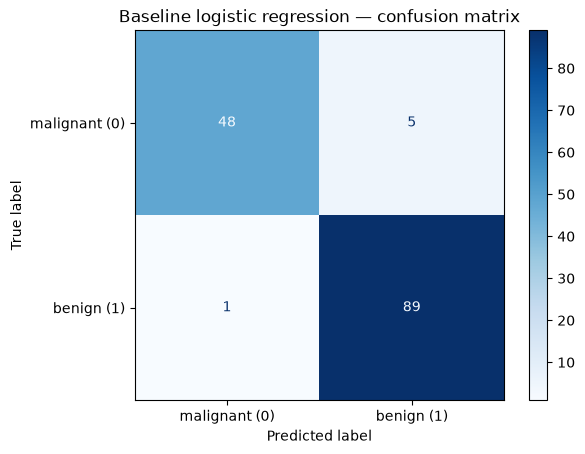

In [59]:
cm = confusion_matrix(y_test, y_pred_baseline, labels=[0, 1])
display(pd.DataFrame(cm,
    index=["Actual malignant", "Actual benign"],
    columns=["Predicted malignant", "Predicted benign"]))

ConfusionMatrixDisplay(confusion_matrix=cm,
    display_labels=["malignant (0)", "benign (1)"]).plot(cmap="Blues", values_format="d")
plt.title("Baseline logistic regression — confusion matrix")
plt.show()

### Common metrics

- **Accuracy** = fraction of all predictions that are correct.
- **Precision for malignant** = fraction of predicted malignant cases that are actually malignant.
- **Recall for malignant** = fraction of actual malignant cases correctly identified.
- **F1 for malignant** = harmonic mean of malignant precision and recall.
- **Balanced accuracy** = mean recall across both classes; particularly informative when labels are imbalanced.

A **false negative for malignant disease** means an actual malignant sample was labeled benign. In this dataset encoding, that corresponds to row 0, column 1 of the matrix.

In [60]:
def classification_metrics(y_true, y_pred):
    """Return metrics, treating malignant (label 0) as the class of interest."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_malignant": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "recall_malignant": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "f1_malignant": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
    }

display(pd.Series(classification_metrics(y_test, y_pred_baseline)).round(3))
print(classification_report(y_test, y_pred_baseline,
                            labels=[0, 1], target_names=["malignant", "benign"]))

accuracy               0.958
balanced_accuracy      0.947
precision_malignant    0.980
recall_malignant       0.906
f1_malignant           0.941
dtype: float64

              precision    recall  f1-score   support

   malignant       0.98      0.91      0.94        53
      benign       0.95      0.99      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



**Discussion:** Why might recall for malignant samples be more important than overall accuracy in some screening scenarios? Why might precision also matter? Neither metric alone fully describes the consequences of errors.

## 6. Preprocessing with StandardScaler

Features can have very different ranges. `StandardScaler` uses training-set statistics to calculate

$$z_j = \frac{x_j - \mu_j}{\sigma_j}$$

for each feature $j$, where $\mu_j$ and $\sigma_j$ are estimated **on the training set**. Scaling is typically useful for distance-based methods and regularized linear models; decision trees generally do not need it.

**Never use `fit_transform` on the test set.** That would allow test-set information to influence preprocessing (data leakage).

In [61]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # learn statistics + transform
X_test_scaled = scaler.transform(X_test)        # reuse training statistics

print("Original first three feature means:", X_train.iloc[:, :3].mean().round(2).to_list())
print("Scaled train means:", np.round(X_train_scaled[:, :3].mean(axis=0), 5))
print("Scaled train stds:", np.round(X_train_scaled[:, :3].std(axis=0), 5))
print("Learned scaler attributes:", "mean_", scaler.mean_.shape,
      "scale_", scaler.scale_.shape)

Original first three feature means: [14.08, 19.3, 91.59]
Scaled train means: [-0.  0. -0.]
Scaled train stds: [1. 1. 1.]
Learned scaler attributes: mean_ (30,) scale_ (30,)


In [62]:
scaled_logistic = LogisticRegression(max_iter=5000)
scaled_logistic.fit(X_train_scaled, y_train)
y_pred_scaled = scaled_logistic.predict(X_test_scaled)

metrics_so_far = pd.DataFrame({
    "Logistic regression (raw)": classification_metrics(y_test, y_pred_baseline),
    "Logistic regression (scaled)": classification_metrics(y_test, y_pred_scaled),
}).T
display(metrics_so_far.round(3))

,accuracy,balanced_accuracy,precision_malignant,recall_malignant,f1_malignant
Logistic regression (raw),0.958,0.947,0.980,0.906,0.941
Logistic regression (scaled),0.986,0.985,0.981,0.981,0.981


## 7. Pipelines: the recommended pattern

A `Pipeline` joins a transformer and an estimator into a single object. On `fit`, the scaler learns statistics from the provided training fold; on `predict`, it transforms incoming rows with those saved statistics before classification.

A pipeline is especially valuable during cross-validation, because preprocessing is **re-fit separately inside each training fold**.

In [63]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])
logistic_pipeline.fit(X_train, y_train)
y_pred_pipeline = logistic_pipeline.predict(X_test)

print("Pipeline accuracy:", round(accuracy_score(y_test, y_pred_pipeline), 3))
print("Pipeline steps:", list(logistic_pipeline.named_steps))
print("Matches manual scaling predictions:",
      np.array_equal(y_pred_pipeline, y_pred_scaled))

Pipeline accuracy: 0.986
Pipeline steps: ['scaler', 'classifier']
Matches manual scaling predictions: True


### Inspect fitted components and model parameters

`get_params()` returns **configuration choices** (hyperparameters). Attributes ending in `_` typically contain **quantities learned during `fit`**. For logistic regression, `coef_` and `intercept_` are fitted model parameters. For the scaler, `mean_` contains training-set feature means.

In [64]:
print("Configured regularization C:",
      logistic_pipeline.named_steps["classifier"].get_params()["C"])
print("First 5 scaler training means:",
      logistic_pipeline.named_steps["scaler"].mean_[:5].round(2))
print("Coefficient shape:", logistic_pipeline.named_steps["classifier"].coef_.shape)

coefficients = pd.Series(logistic_pipeline.named_steps["classifier"].coef_[0], index=X.columns)
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10).round(3))

Configured regularization C: 1.0
First 5 scaler training means: [1.4080e+01 1.9300e+01 9.1590e+01 6.4963e+02 1.0000e-01]
Coefficient shape: (1, 30)


worst texture          -1.250
radius error           -1.070
worst symmetry         -0.957
worst concave points   -0.942
area error             -0.941
worst area             -0.926
worst radius           -0.917
worst concavity        -0.797
worst perimeter        -0.721
mean compactness        0.694
dtype: float64

Coefficients here are associated with **standardized** variables. Their magnitude is not, by itself, proof of causal importance: features may be correlated.

## 8. Compare different estimators

scikit-learn lets us swap the last pipeline step without redesigning the workflow:

- **k-nearest neighbors (kNN):** predicts from nearby training examples; strongly affected by feature scale.
- **Decision tree:** splits on feature thresholds; scaling is generally unnecessary.
- **Logistic regression:** linear decision boundary in the transformed feature space.

For now, use the **same train/test split** for a transparent demonstration. In a real selection workflow, compare candidates with training-set cross-validation and reserve the test set for the final estimate (Section 10).

In [65]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])
tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)

# Illustration only: test-set comparison is NOT the model selection criterion.
models_demo = {
    "Logistic regression": logistic_pipeline,
    "kNN (k=5)": knn_pipeline,
    "Decision tree (depth=4)": tree,
}
for model in models_demo.values():
    model.fit(X_train, y_train)

example_comparison = pd.DataFrame({
    name: classification_metrics(y_test, model.predict(X_test))
    for name, model in models_demo.items()
}).T
display(example_comparison.round(3))

,accuracy,balanced_accuracy,precision_malignant,recall_malignant,f1_malignant
Logistic regression,0.986,0.985,0.981,0.981,0.981
kNN (k=5),0.979,0.972,1.000,0.943,0.971
Decision tree (depth=4),0.944,0.940,0.925,0.925,0.925


### Visualize a small part of the fitted decision tree

Trees make predictions by repeated feature-threshold tests. We plot only the first levels for readability.

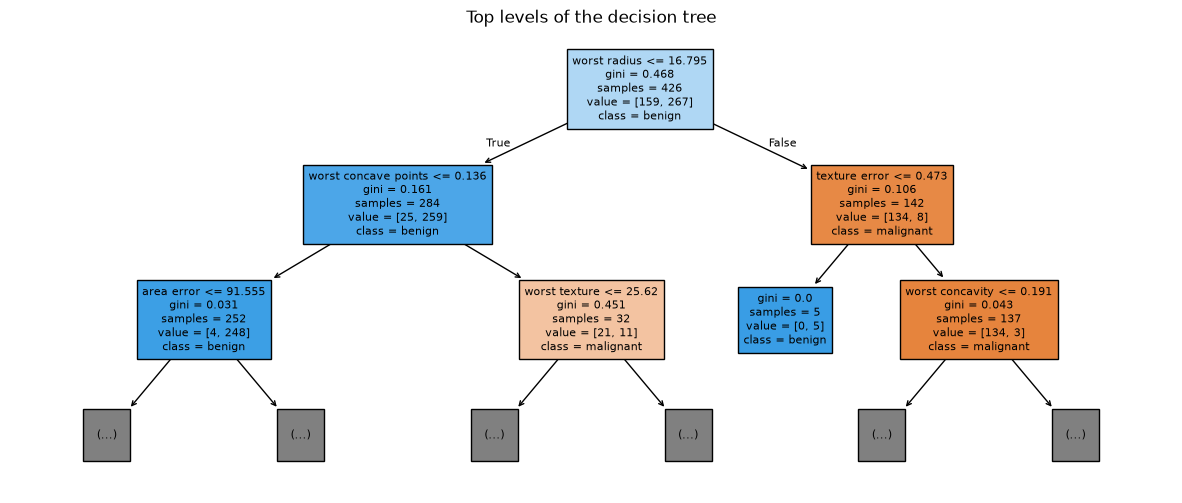

,tree_importance
worst radius,0.726829
worst concave points,0.122113
texture error,0.048398
worst texture,0.033231
worst concavity,0.018188
mean concave points,0.014158
area error,0.012613
mean texture,0.012585


In [66]:
plt.figure(figsize=(15, 6))
plot_tree(tree, feature_names=list(X.columns),
          class_names=["malignant", "benign"],
          filled=True, max_depth=2, fontsize=8)
plt.title("Top levels of the decision tree")
plt.show()

importance = pd.Series(tree.feature_importances_, index=X.columns)
display(importance.sort_values(ascending=False).head(8).to_frame("tree_importance"))

**Interpretation warning:** Tree `feature_importances_` summarizes the fitted tree's split-based importance; it does not demonstrate a causal medical relationship.

## 9. Predicted probabilities and decision thresholds

Some classifiers support `predict_proba(X)`. The resulting columns correspond to `model.classes_`, **not** automatically to a condition of clinical interest.

For our labels, class 0 is **malignant** and class 1 is **benign**. We explicitly locate the column for class 0 before extracting probabilities.

In [67]:
proba = logistic_pipeline.predict_proba(X_test)
classes = logistic_pipeline.named_steps["classifier"].classes_
malignant_col = np.where(classes == 0)[0][0]
p_malignant = proba[:, malignant_col]

print("Class order:", classes)
display(pd.DataFrame({
    "P(malignant)": p_malignant[:8],
    "P(benign)": proba[:8, np.where(classes == 1)[0][0]],
    "predicted_label": logistic_pipeline.predict(X_test)[:8],
    "actual_label": y_test.iloc[:8].to_numpy(),
}).round(3))

Class order: [0 1]


,P(malignant),P(benign),predicted_label,actual_label
0,0.031,0.969,1,1
1,1.000,0.000,0,0
2,0.441,0.559,1,1
3,0.061,0.939,1,1
4,0.825,0.175,0,0
5,1.000,0.000,0,0
6,0.997,0.003,0,0
7,0.999,0.001,0,0


Changing a threshold alters the tradeoff between missing malignant cases and flagging benign cases. With the rule **predict malignant if** `P(malignant) >= threshold`, a lower threshold generally increases malignant recall but may reduce malignant precision.

**Teaching demonstration only:** the thresholds below are evaluated on held-out data to illustrate their effects. In a genuine deployment workflow, choose the threshold from validation data (or out-of-fold training predictions), **not** from the test results.

In [68]:
threshold_rows = []
for threshold in [0.2, 0.5, 0.8]:
    threshold_predictions = np.where(p_malignant >= threshold, 0, 1)
    threshold_rows.append({"threshold": threshold,
                           **classification_metrics(y_test, threshold_predictions)})
display(pd.DataFrame(threshold_rows).set_index("threshold").round(3))

,accuracy,balanced_accuracy,precision_malignant,recall_malignant,f1_malignant
threshold,,,,,
0.2,0.951,0.957,0.897,0.981,0.937
0.5,0.986,0.985,0.981,0.981,0.981
0.8,0.972,0.962,1.000,0.925,0.961


## 10. Cross-validation: better model assessment on training data

A single split may give an unstable result. **Stratified k-fold cross-validation** partitions the training set into folds, fits the model on $k-1$ folds, and scores it on the remaining fold, repeating for each fold.

Since the scaler is **inside** each pipeline, it cannot learn from the validation fold. We use malignant recall as one illustrative metric, but model choice depends on the real application.

In [69]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "kNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

cv_rows = []
for name, estimator in cv_models.items():
    result = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "macro_recall": "recall_macro"}
    )
    cv_rows.append({
        "model": name,
        "mean_accuracy": result["test_accuracy"].mean(),
        "sd_accuracy": result["test_accuracy"].std(),
        "mean_macro_recall": result["test_macro_recall"].mean(),
    })
display(pd.DataFrame(cv_rows).set_index("model").round(3))

,mean_accuracy,sd_accuracy,mean_macro_recall
model,,,
Logistic regression,0.979,0.009,0.974
kNN (k=5),0.967,0.014,0.959
Decision tree,0.927,0.019,0.924


**Metric note:** `recall_macro` is the unweighted mean of recall for both classes, **not** malignant-only recall. For malignant recall specifically, we can use a scorer with `pos_label=0` (next cell).

In [70]:
from sklearn.metrics import make_scorer
malignant_recall_scorer = make_scorer(recall_score, pos_label=0)
cv_recall = cross_validate(
    cv_models["Logistic regression"], X_train, y_train,
    cv=cv, scoring={"malignant_recall": malignant_recall_scorer}
)
print("Malignant recall across folds:",
      np.round(cv_recall["test_malignant_recall"], 3))
print("Mean malignant recall:",
      round(cv_recall["test_malignant_recall"].mean(), 3))

Malignant recall across folds: [0.938 0.938 0.938 0.969 1.   ]
Mean malignant recall: 0.956


## 11. Hyperparameter tuning without touching the test set

The value `n_neighbors` is a **hyperparameter** of kNN: it is chosen before a model is fitted. `GridSearchCV` evaluates a grid of choices using cross-validation on **training data only**.

Here we optimize balanced accuracy; other choices may be more suitable when the costs of false negatives and false positives differ.

In [71]:
knn_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier())
    ]),
    param_grid={"classifier__n_neighbors": [3, 5, 7, 9, 11, 15]},
    scoring="balanced_accuracy",
    cv=cv,
    refit=True
)
knn_search.fit(X_train, y_train)
print("Selected hyperparameters:", knn_search.best_params_)
print("Mean CV balanced accuracy:", round(knn_search.best_score_, 3))

tuning = pd.DataFrame(knn_search.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score"]
].rename(columns={"param_classifier__n_neighbors": "k",
                  "mean_test_score": "mean_CV_balanced_accuracy",
                  "std_test_score": "sd_CV_balanced_accuracy"})
display(tuning.round(3))

Selected hyperparameters: {'classifier__n_neighbors': 9}
Mean CV balanced accuracy: 0.962


,k,mean_CV_balanced_accuracy,sd_CV_balanced_accuracy
0,3,0.954,0.020
1,5,0.959,0.021
2,7,0.956,0.020
3,9,0.962,0.015
4,11,0.960,0.011
5,15,0.956,0.022


### Final evaluation on held-out data

After setting the hyperparameters using cross-validation, the selected pipeline is refitted on all the training data. **Now** we evaluate that fitted pipeline on the untouched test set.

For a production research study, the entire model/feature/threshold selection strategy should likewise be fixed without relying on test performance.

accuracy               0.965
balanced_accuracy      0.953
precision_malignant    1.000
recall_malignant       0.906
f1_malignant           0.950
Name: Final held-out test score, dtype: float64

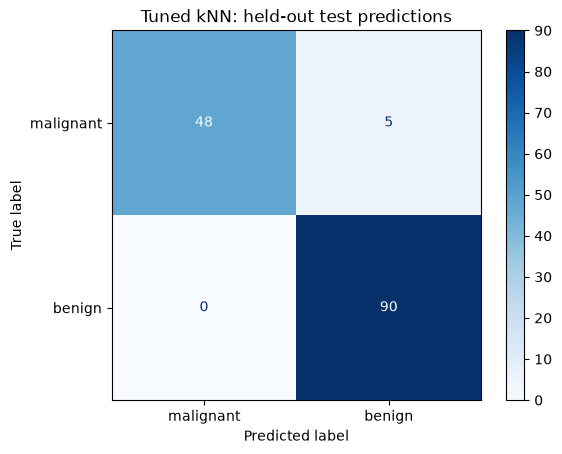

In [72]:
final_model = knn_search.best_estimator_
final_predictions = final_model.predict(X_test)
display(pd.Series(classification_metrics(y_test, final_predictions),
                  name="Final held-out test score").round(3))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_predictions, labels=[0, 1],
    display_labels=["malignant", "benign"], cmap="Blues"
)
plt.title("Tuned kNN: held-out test predictions")
plt.show()

## 12. Probability calibration

A model can classify patients correctly while producing unreliable probabilities. **Calibration** asks whether predictions such as “70% chance of malignancy” correspond to approximately 70% malignant cases among patients receiving similar predictions. Discrimination (separating cases) and calibration (reliability of probabilities) are different properties.

For a binary outcome $Y\in\{0,1\}$, ideal calibration informally means $P(Y=1\mid \hat p=p)=p$. Here **malignant = class 0**, so we explicitly use $P(Y=0\mid X)$ throughout.

A *reliability diagram* groups predicted probabilities into bins and compares their average with the observed frequency. The diagonal is perfect calibration. The **Brier score** is the mean squared error of probabilistic predictions: $\mathrm{Brier}=\frac{1}{n}\sum_i (p_i-z_i)^2$, where $z_i=1$ means malignant. Lower is better.

**Good practice:** Assess calibration using predictions on data not used to fit that model. We use out-of-fold predictions within the training set below, leaving the held-out test set untouched.

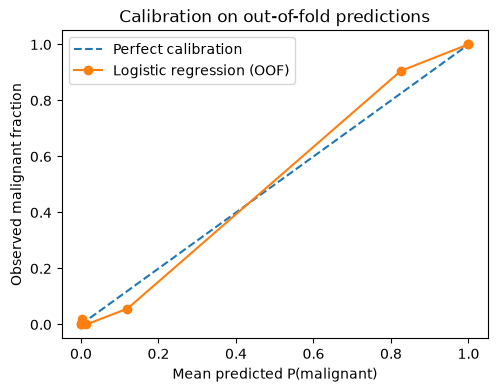

Out-of-fold Brier score: 0.0183


In [73]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

calibration_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
# Each probability here is predicted by a model fitted on the other CV folds.
oof_probs = cross_val_predict(
    calibration_model, X_train, y_train, cv=cv, method="predict_proba"
)
oof_malignant_prob = oof_probs[:, 0]  # classes are ordered [0, 1]
y_malignant_train = (y_train.to_numpy() == 0).astype(int)

fraction_positive, mean_predicted = calibration_curve(
    y_malignant_train, oof_malignant_prob, n_bins=8, strategy="quantile"
)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
ax.plot(mean_predicted, fraction_positive, "o-", label="Logistic regression (OOF)")
ax.set(xlabel="Mean predicted P(malignant)",
       ylabel="Observed malignant fraction", title="Calibration on out-of-fold predictions")
ax.legend()
plt.show()
print("Out-of-fold Brier score:",
      round(brier_score_loss(y_malignant_train, oof_malignant_prob), 4))

### Improving calibration

`CalibratedClassifierCV` learns a probability calibration mapping using cross-validation. With `method='sigmoid'`, it fits a sigmoid calibrator; `method='isotonic'` uses a more flexible monotonic mapping, but can overfit on small calibration sets. Calibration is **not** a substitute for choosing a clinically meaningful decision threshold.

The following example fits a calibrated classifier on training data only. Its scores should be assessed on independent data once model-selection decisions are frozen.

In [74]:
calibrated_model = CalibratedClassifierCV(
    estimator=make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    method="sigmoid", cv=3
)
calibrated_model.fit(X_train, y_train)
print("Calibrated probability for first example [malignant, benign]:")
print(np.round(calibrated_model.predict_proba(X_train.iloc[:1]), 3))

Calibrated probability for first example [malignant, benign]:
[[0.984 0.016]]


**Try it:** Compare `sigmoid` and `isotonic` calibration using cross-validated probabilities on training data. What happens to the Brier score? Does a lower Brier score guarantee higher recall? (No: these measure different aspects.)

## 13. Class imbalance and class-sensitive evaluation

If one class is rare, a high overall accuracy can conceal poor recognition of that class. Always inspect **class prevalence**, the confusion matrix, class-specific recall/precision, and metrics such as balanced accuracy. On this dataset, **malignant = 0**, so the ordinary binary scorer defaults must be checked.

Some estimators support `class_weight='balanced'`, which upweights classes inversely to their frequency. Other approaches include resampling, but **resampling must happen inside each CV training fold**, not before splitting the dataset. Class weighting is not guaranteed to improve every metric: it changes the trade-off between false positives and false negatives.

In [75]:
print("Training class proportions (0 = malignant, 1 = benign):")
print(y_train.value_counts(normalize=True).sort_index().round(3))

weight_models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Weighted logistic regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")
    ),
}
from sklearn.metrics import make_scorer
comparison = []
for label, estimator in weight_models.items():
    metrics_cv = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"balanced_accuracy": "balanced_accuracy",
                 "malignant_recall": make_scorer(recall_score, pos_label=0),
                 "malignant_precision": make_scorer(precision_score, pos_label=0, zero_division=0)}
    )
    comparison.append({"model": label, **{
        metric.replace("test_", ""): values.mean()
        for metric, values in metrics_cv.items() if metric.startswith("test_")
    }})
display(pd.DataFrame(comparison).set_index("model").round(3))

Training class proportions (0 = malignant, 1 = benign):
target
0    0.373
1    0.627
Name: proportion, dtype: float64


,balanced_accuracy,malignant_recall,malignant_precision
model,,,
Logistic regression,0.974,0.956,0.987
Weighted logistic regression,0.974,0.962,0.975


**Exercise:** Which model has the better malignant recall? What happens to precision? Would you use class weights for every problem? Discuss whether the relative clinical costs of missed cancers and false alarms matter more than optimizing any one score.

## 14. ROC curves and precision–recall curves

A model that outputs scores or probabilities can be evaluated at **many thresholds**, not just the default one.

- **ROC curve:** true positive rate (recall) versus false positive rate ($1-\mathrm{specificity}$). ROC AUC summarizes ranking across thresholds.
- **Precision–recall (PR) curve:** precision versus recall; **average precision (AP)** summarizes the precision–recall trade-off. PR plots are especially informative when the positive class is uncommon, and their baseline depends on prevalence.

**Important label convention:** In this notebook malignancy is label **0**. For these figures we convert the target to `1 = malignant` and use the **probability of class 0**. We use out-of-fold training predictions to avoid showing overly optimistic in-sample curves.

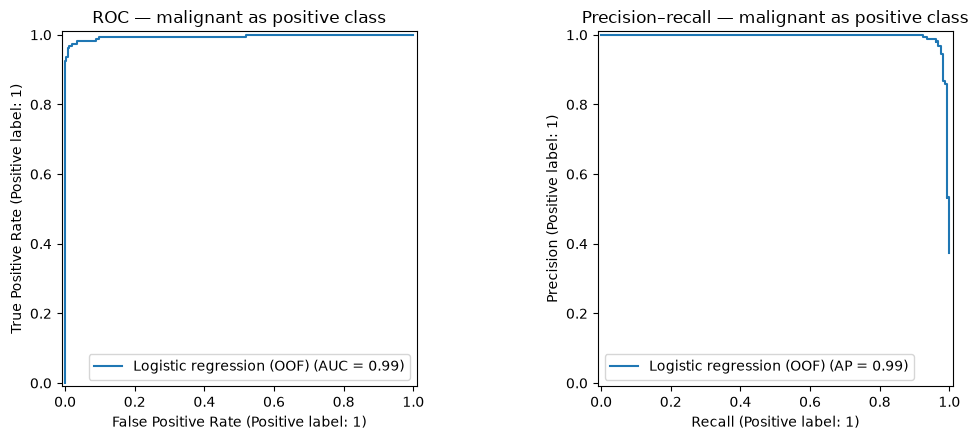

ROC AUC: 0.995
Average precision: 0.994


In [76]:
from sklearn.metrics import (
    RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score, average_precision_score
)

scores_malignant = oof_malignant_prob  # out-of-fold scores from section 12
labels_malignant = y_malignant_train  # explicitly 1 = malignant

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(labels_malignant, scores_malignant, ax=axes[0],
                                 name="Logistic regression (OOF)")
PrecisionRecallDisplay.from_predictions(labels_malignant, scores_malignant, ax=axes[1],
                                        name="Logistic regression (OOF)")
axes[0].set_title("ROC — malignant as positive class")
axes[1].set_title("Precision–recall — malignant as positive class")
plt.tight_layout()
plt.show()
print("ROC AUC:", round(roc_auc_score(labels_malignant, scores_malignant), 3))
print("Average precision:", round(average_precision_score(labels_malignant, scores_malignant), 3))

### Threshold exercise

Lower the threshold for declaring *malignant* and examine how recall, precision, and the number of false alarms change. A threshold should be selected on validation data with the clinical application in mind, **not by maximizing performance on the held-out test set**.

In [77]:
rows = []
for threshold in [0.2, 0.35, 0.5, 0.65, 0.8]:
    predicted_malignant = (scores_malignant >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "malignant_recall": recall_score(labels_malignant, predicted_malignant),
        "malignant_precision": precision_score(
            labels_malignant, predicted_malignant, zero_division=0),
        "flagged_malignant": int(predicted_malignant.sum())
    })
display(pd.DataFrame(rows).set_index("threshold").round(3))

,malignant_recall,malignant_precision,flagged_malignant
threshold,,,
0.20,0.981,0.923,169
0.35,0.975,0.957,162
0.50,0.956,0.987,154
0.65,0.925,1.000,147
0.80,0.899,1.000,143


## 15. Grouping by patient: avoid subject-level leakage

In real clinical datasets, a patient may contribute multiple images, visits, or measurements. Randomly splitting **rows** can place records of the same patient in both training and validation, producing overly optimistic performance.

- `GroupKFold`: assigns each patient entirely to either training or validation within a split.
- `StratifiedGroupKFold`: also tries to preserve class proportions, subject to group constraints.

The Breast Cancer Wisconsin dataset in this notebook does **not** provide patient IDs for demonstrating repeated-patient groups. We therefore use a **separate synthetic example** (not actual patient information).

In [78]:
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold

# Synthetic example: 12 patients, 2 observations per patient.
# Groups repeat because each patient has multiple visits.
synthetic_patient_ids = np.repeat(np.arange(12), 2)
synthetic_labels = np.repeat([0, 1] * 6, 2)
synthetic_features = pd.DataFrame({
    "measurement": np.arange(24, dtype=float),
    "visit": np.tile([1, 2], 12)
})

group_cv = GroupKFold(n_splits=3)
for fold, (tr, va) in enumerate(
    group_cv.split(synthetic_features, synthetic_labels, groups=synthetic_patient_ids), start=1
):
    tr_patients = set(synthetic_patient_ids[tr])
    va_patients = set(synthetic_patient_ids[va])
    print(f"Fold {fold}: train patients={sorted(tr_patients)}, "
          f"validation patients={sorted(va_patients)}, "
          f"overlap={len(tr_patients & va_patients)}")

Fold 1: train patients=[np.int64(0), np.int64(1), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(9), np.int64(10)], validation patients=[np.int64(2), np.int64(5), np.int64(8), np.int64(11)], overlap=0
Fold 2: train patients=[np.int64(0), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(11)], validation patients=[np.int64(1), np.int64(4), np.int64(7), np.int64(10)], overlap=0
Fold 3: train patients=[np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11)], validation patients=[np.int64(0), np.int64(3), np.int64(6), np.int64(9)], overlap=0


**Exercise:** Replace `GroupKFold` with `StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)` and inspect the class proportions in each validation fold. Why is perfect stratification sometimes impossible when groups differ in size or class composition?

**Practical rule:** When you have real patient IDs, pass them as `groups` into CV splitting and hyperparameter search. Group-level test splitting matters too: the final holdout must not share patients with the training data.

## 16. External validation and distribution shift

**Internal cross-validation** tests performance on held-out subsets sampled from the same development dataset. **External validation** evaluates a frozen model on a genuinely independent cohort (for example, another hospital, device, time period, or geographic location).

External cohorts may differ in disease prevalence, patient demographics, measurement procedures, or missingness patterns. This is often called *distribution shift*. A model can perform well in internal CV yet perform poorly externally.

**A reproducible external validation protocol:**

1. Define the intended clinical population and target in advance.
2. Freeze preprocessing, feature selection, model architecture, hyperparameters, calibration, and decision threshold using development data only.
3. Obtain a genuinely independent external dataset; ensure patient overlap is excluded.
4. Apply the fitted pipeline **without calling `fit()`** on external patients.
5. Report class prevalence, confusion matrix, sensitivity, specificity, precision, calibration, and uncertainty intervals; inspect relevant patient subgroups.

We do **not** have an external cohort attached to this notebook. The cell below is a **template only**, not an external validation experiment.

In [79]:
# Template: execute only if a genuinely independent external dataset is available.
# X_external = ...  # same features / units / order as used in training
# y_external = ...  # compatible label coding: 0=malignant, 1=benign
# external_pred = final_model.predict(X_external)
# external_prob_malignant = final_model.predict_proba(X_external)[:, 0]
# print(classification_metrics(y_external, external_pred))
# print("External prevalence of malignancy:", (y_external == 0).mean())

**Discussion / project task:** Imagine deploying the classifier at another hospital. What could change between sites? Which checks would you make before claiming that the model generalizes? Why is the existing 25% held-out split an *internal* test, not external validation?

## 17. Introduction to neural networks with scikit-learn

Scikit-learn includes a **multi-layer perceptron (MLP)** classifier: `MLPClassifier`. Unlike a decision tree, an MLP learns several successive *layers* of weighted transformations followed by nonlinear activation functions.

An MLP with one hidden layer computes (schematically):

$$
 h = \sigma(W_1 x + b_1), \qquad \hat{y} = g(W_2 h + b_2).
$$

- `hidden_layer_sizes=(32,)` means **one hidden layer of 32 neurons**.
- `hidden_layer_sizes=(32, 16)` means **two hidden layers**, with 32 and 16 neurons respectively.
- `activation='relu'` specifies the nonlinear activation in hidden layers.
- `alpha` controls L2 regularization of the network weights.
- `learning_rate_init` is the initial step size for the optimizer (for the default `solver='adam'`).
- `max_iter` is the maximum number of training **epochs** for the stochastic optimizers, not the number of mini-batches.

`MLPClassifier` optimizes its parameters during `fit()`, using gradient-based training internally. It is not a neural-network framework like PyTorch: you cannot freely define arbitrary architectures and training loops, but it is very convenient for comparing a simple NN with other scikit-learn classifiers.

**Important:** neural networks are sensitive to feature scales. Place `StandardScaler` inside a `Pipeline` so that every CV fold learns its own preprocessing statistics.

In [80]:
from sklearn.neural_network import MLPClassifier

nn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32,),
        activation="relu",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=700,
        random_state=RANDOM_STATE
    ))
])

nn_pipeline.fit(X_train, y_train)
nn_predictions = nn_pipeline.predict(X_test)
print("NN held-out accuracy:", round(accuracy_score(y_test, nn_predictions), 3))
print("NN held-out balanced accuracy:", round(balanced_accuracy_score(y_test, nn_predictions), 3))
print("NN held-out malignant recall:", round(recall_score(y_test, nn_predictions, pos_label=0), 3))

NN held-out accuracy: 0.965
NN held-out balanced accuracy: 0.968
NN held-out malignant recall: 0.981


### Inspect the fitted network

The trained estimator is available through `named_steps`. Its attributes include:

- `coefs_`: a list of learned weight matrices, one per connection between layers;
- `intercepts_`: the learned bias vectors;
- `n_layers_`: number of network layers, **including input and output**;
- `n_iter_`: number of epochs performed;
- `loss_curve_`: training loss recorded during optimization (with the default `adam` solver).

For 30 input features, 32 hidden units, and a single binary output, `coefs_` has shapes `(30, 32)` and `(32, 1)`. These are **learned parameters**, not hyperparameters such as `hidden_layer_sizes`. The loss curve is based on training, so a decreasing training loss does *not* prove better generalization.

Number of network layers: 3
Weight matrix shapes: [(30, 32), (32, 1)]
Epochs completed: 359


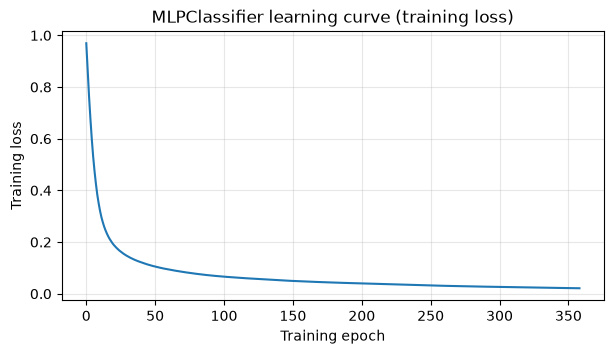

In [81]:
fitted_nn = nn_pipeline.named_steps["classifier"]
print("Number of network layers:", fitted_nn.n_layers_)
print("Weight matrix shapes:", [w.shape for w in fitted_nn.coefs_])
print("Epochs completed:", fitted_nn.n_iter_)

plt.figure(figsize=(7, 3.5))
plt.plot(fitted_nn.loss_curve_)
plt.xlabel("Training epoch")
plt.ylabel("Training loss")
plt.title("MLPClassifier learning curve (training loss)")
plt.grid(alpha=0.3)
plt.show()

## 18. Guided exercise — Hyperparameter search for a neural network

**Goal:** Use `GridSearchCV` to find a suitable MLP architecture and regularization strength **using only `X_train` / `y_train`**. Do not use the test set for choosing settings.

**Tasks**

1. Create a `Pipeline` with `StandardScaler` and `MLPClassifier(random_state=RANDOM_STATE, max_iter=700)`.
2. Set a parameter grid with `hidden_layer_sizes` in `[(16,), (32,), (32, 16)]` and `alpha` in `[0.0001, 0.01]`. How many configurations are there?
3. Use `GridSearchCV` with a **3-fold stratified CV**, `scoring='balanced_accuracy'`, and `refit=True`. How many CV fits are performed? How many total fits, including the refit?
4. Show `best_params_`, `best_score_`, and a table containing mean and standard deviation of validation scores from `cv_results_`.
5. Inspect the chosen architecture via `best_estimator_.named_steps['classifier']` and its weight matrix shapes.
6. **Reflection:** Why must the scaler be *inside* the pipeline? Why should you not use the test-set accuracy to select the grid?

**Optional extension:** Add `learning_rate_init` to the grid. Discuss why the number of fits grows multiplicatively and why neural network results can depend on random initialization.

The small grid is for classroom use rather than exhaustive tuning. Optimization convergence warnings can arise; they mean an iteration limit was reached, not necessarily that the code failed.

In [82]:
# EXERCISE: Fill in the TODOs, then run the cell.
from sklearn.neural_network import MLPClassifier

mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        max_iter=700,
        random_state=RANDOM_STATE
    ))
])

mlp_param_grid = {
    "classifier__hidden_layer_sizes": [(16,), (32,), (32, 16)],
    "classifier__alpha": [0.0001, 0.01],
}

# TODO: define StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
# TODO: construct GridSearchCV(mlp_pipe, mlp_param_grid, cv=..., scoring=..., refit=True)
# TODO: fit using X_train, y_train
# TODO: display best parameters, mean CV score, and the results table
# TODO: inspect the selected neural network's weight matrix shapes

<details>
<summary><strong>Suggested exercise solution (expand after trying)</strong></summary>

```python
mlp_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
mlp_search = GridSearchCV(
    estimator=mlp_pipe,
    param_grid=mlp_param_grid,
    scoring="balanced_accuracy",
    cv=mlp_cv,
    refit=True,
    n_jobs=1,
)
mlp_search.fit(X_train, y_train)
print("Best settings:", mlp_search.best_params_)
print("Mean CV balanced accuracy:", mlp_search.best_score_)

results = pd.DataFrame(mlp_search.cv_results_)
display(results[["params", "mean_test_score", "std_test_score"]]
        .sort_values("mean_test_score", ascending=False))

best_nn = mlp_search.best_estimator_.named_steps["classifier"]
print([w.shape for w in best_nn.coefs_])
```

There are **3 × 2 = 6 configurations**, **6 × 3 = 18 CV fits**, plus **1 refit = 19 total fits**. All configurations use the same three validation folds. Do not add test results to the grid-search selection procedure.
</details>

## 19. Common pitfalls and practical checklist

**Common mistakes**
1. Scaling the entire dataset before splitting → leakage.
2. Running `scaler.fit_transform(X_test)` → different train/test transformations and test leakage.
3. Choosing a model, threshold, or feature set repeatedly based on test scores → optimistic evaluation.
4. Interpreting label `1` as “malignant” without checking the label mapping.
5. Using accuracy alone when some errors are much more consequential than others.
6. Assuming predicted probabilities are perfectly calibrated.

**Checklist:** inspect labels → split → pipeline → cross-validation/tuning on train → one final evaluation on test → document limitations.

For patient-level datasets, also split by **patient**, not by record, when multiple records come from the same person. Temporal data may require a chronological split rather than a random one.

## 21. Recap

- `fit` learns parameters from training data; `predict` applies a fitted model.
- `transform` applies a learned transformation; `fit_transform` combines fitting and transforming.
- Training and test sets serve **different purposes**.
- Pipelines help prevent preprocessing leakage, especially during cross-validation.
- Class-label encoding changes how you interpret probabilities, recall, and confusion matrices.
- Use cross-validation for comparing choices, then evaluate the final procedure on untouched test data.

The notebook now includes dedicated sections on **calibration, class imbalance, ROC/precision–recall curves, patient-level groups, and external validation**, followed by the introduction to neural networks and the NN hyperparameter-search exercise.
